## Import and Reading Data

In [1]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import numpy as np
import sklearn
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import LeakyReLU

## Load Train and Test Datasets

In [3]:
# Load training data
df_train = pd.read_csv('D:/X-AI PROJECT/0_Datasets/ML-Based IDS IoMT/Dataset & Captures/Datasets/IP-Based/Flows/train.csv')

In [4]:
# Load testing data
df_test = pd.read_csv('D:/X-AI PROJECT/0_Datasets/ML-Based IDS IoMT/Dataset & Captures/Datasets/IP-Based/Flows/test.csv')

In [5]:
X_train = df_train.drop(['is_attack'], axis=1)  # Features
y_train = df_train['is_attack']  # Target variable

In [6]:
X_test = df_test.drop(['is_attack'], axis=1)  # Features
y_test = df_test['is_attack']  # Target variable

In [7]:
X_train, X_train_test, y_train, y_train_test = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

-----
## Create Model and Train Model

In [8]:
X_train.shape,y_train.shape

((58452, 33), (58452,))

In [9]:
X_train_test.shape, y_train_test.shape

((14614, 33), (14614,))

In [10]:
X_test.shape,y_test.shape

((8118, 33), (8118,))

In [11]:
%%time

# Define the model
model = Sequential()
model.add(Dense(128, input_dim=X_train.shape[1], activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.5))
model.add(Dense(256, activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.5))
model.add(Dense(128, activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.5))
model.add(Dense(32, activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.5))
model.add(Dense(1, activation='sigmoid'))

C:\Users\AKASH SENANI\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


CPU times: total: 453 ms
Wall time: 535 ms


In [12]:
# Compile the model with learning rate
optimizer = Adam(learning_rate=0.001)
model.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=['accuracy'])

In [13]:
# Define early stopping
monitor = tf.keras.callbacks.ReduceLROnPlateau(monitor="loss",factor=0.5,mode="min",patience=10,verbose=1,min_lr=1e-7)
checkpoint = ModelCheckpoint('Saved_Models/IoMT_AI_IDS_DNN.keras', monitor='val_loss', save_best_only=True)

In [14]:
# Train the model
history = model.fit(X_train, y_train, validation_data=(X_train_test, y_train_test), epochs=100, batch_size=512, callbacks=[monitor, checkpoint])

Epoch 1/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 12s 49ms/step - accuracy: 0.9661 - loss: 0.1301 - val_accuracy: 0.9903 - val_loss: 0.0638 - learning_rate: 0.0010
Epoch 2/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.9894 - loss: 0.0709 - val_accuracy: 0.9903 - val_loss: 0.0533 - learning_rate: 0.0010
Epoch 3/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.9899 - loss: 0.0652 - val_accuracy: 0.9902 - val_loss: 0.0528 - learning_rate: 0.0010
Epoch 4/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.9898 - loss: 0.0611 - val_accuracy: 0.9902 - val_loss: 0.0509 - learning_rate: 0.0010
Epoch 5/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9899 - loss: 0.0579 - val_accuracy: 0.9902 - val_loss: 0.0508 - learning_rate: 0.0010
Epoch 6/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 6s 49ms/step - accuracy: 0.9900 - loss: 0.0553 - val_accuracy: 0.9902 - val_loss: 0.0507 - learning_rate: 0.0010
Epoch 7/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.9900 - 

In [15]:
# Load the best saved model
best_model = load_model('Saved_Models/IoMT_AI_IDS_DNN.keras')

In [16]:
pred = model.predict(X_train_test)

457/457 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


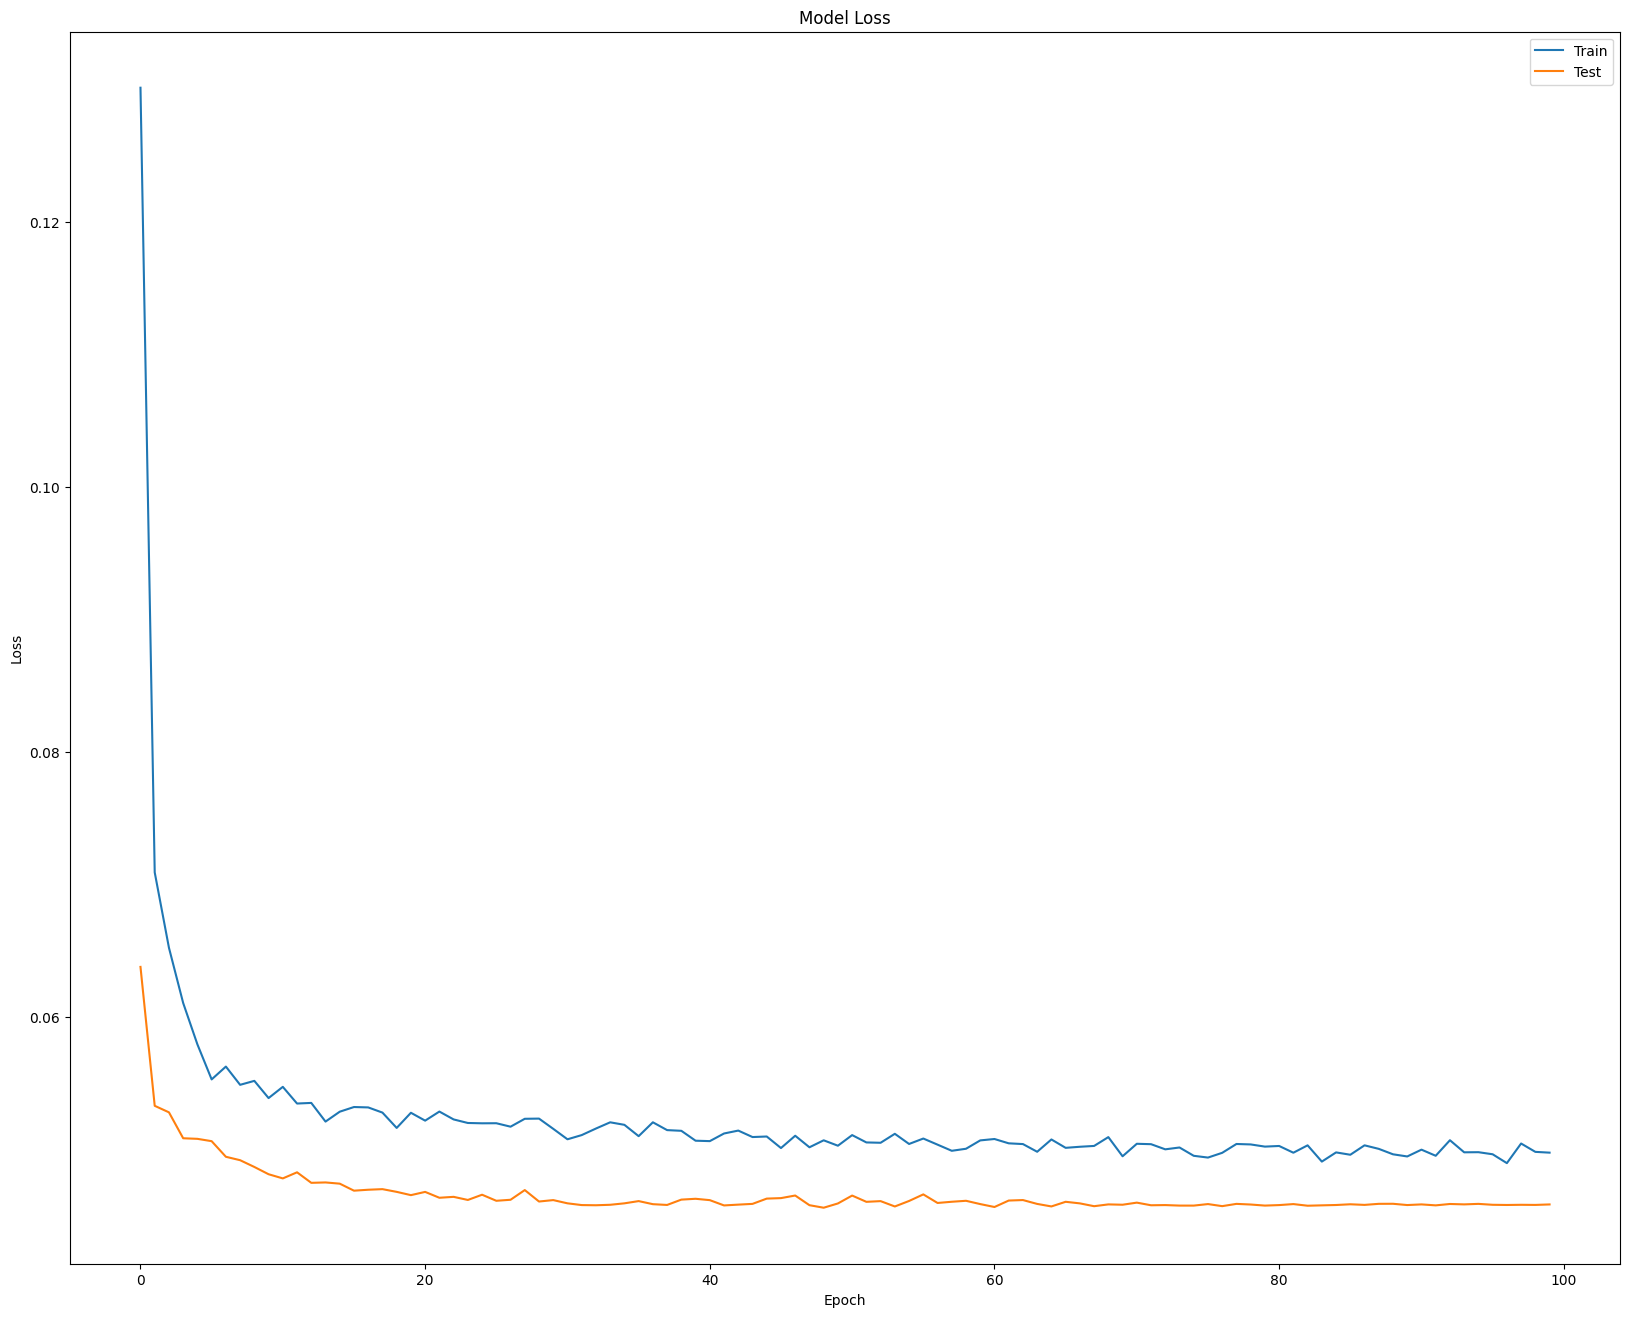

In [17]:
fig, ax = plt.subplots(figsize=(20, 16))

ax.plot(history.history['loss'], label='train')
ax.plot(history.history['val_loss'], label='test')
ax.set_title('Model Loss')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.legend(['Train', 'Test'], loc='upper right')
plt.show()

## Results

### Training

In [18]:
threshold = 0.5  # Adjust the threshold as needed
pred = (pred > threshold).astype(int)

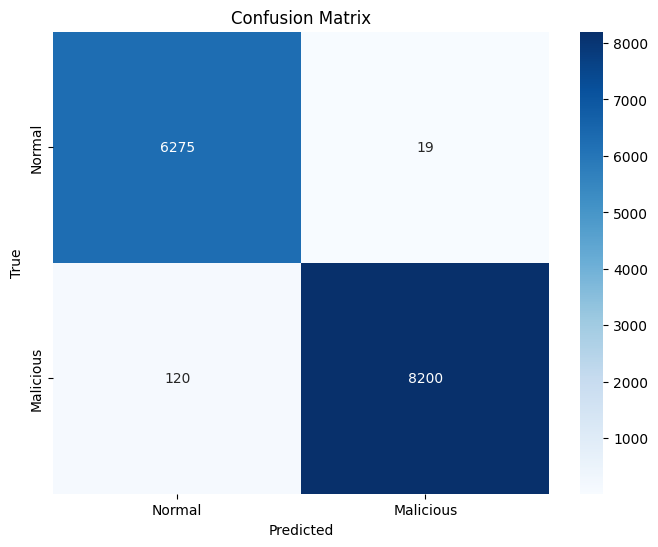

In [19]:
# Compute confusion matrix
cm = confusion_matrix(y_train_test, pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Normal', 'Malicious'], 
            yticklabels=['Normal', 'Malicious'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [20]:
accuracy = accuracy_score(y_train_test, pred)
precision = precision_score(y_train_test, pred)
recall = recall_score(y_train_test, pred)
f1 = f1_score(y_train_test, pred)

print("Accuracy:   {:.2%}".format(accuracy))
print("Precision:  {:.2%}".format(precision))
print("Recall:     {:.2%}".format(recall))
print("F1-score:   {:.2%}".format(f1))

Accuracy:   99.05%
Precision:  99.77%
Recall:     98.56%
F1-score:   99.16%


### with Test Dataset

In [21]:
pred_test = model.predict(X_test)

254/254 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [22]:
threshold = 0.5  # Adjust the threshold as needed
pred_test = (pred_test > threshold).astype(int)

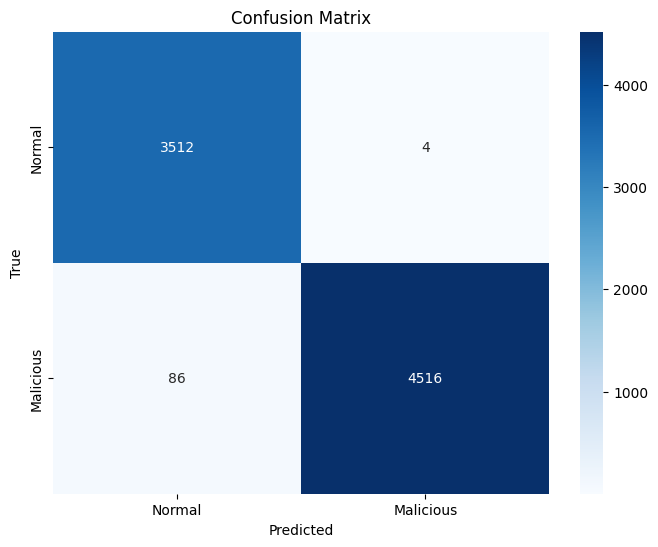

In [23]:
# Compute confusion matrix
cm = confusion_matrix(y_test, pred_test)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Normal', 'Malicious'], 
            yticklabels=['Normal', 'Malicious'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [26]:
# Compute accuracy
accuracy = accuracy_score(y_test, pred_test)
precision = precision_score(y_test, pred_test)
recall = recall_score(y_test, pred_test)
f1 = f1_score(y_test, pred_test)

print("Accuracy:   {:.2%}".format(accuracy))
print("Precision:  {:.2%}".format(precision))
print("Recall:     {:.2%}".format(recall))
print("F1-score:   {:.2%}".format(f1))

Accuracy:   98.89%
Precision:  99.91%
Recall:     98.13%
F1-score:   99.01%


In [27]:
import json
import numpy as np
import pandas as pd

metrics = {
    "dataset": "IoMT-AI-IDS",
    "model": "DNN",
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1)
}

with open("Saved_Models/IoMT_AI_IDS_DNN_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("IoMT AI IDS DNN metrics saved successfully.")

IoMT AI IDS DNN metrics saved successfully.


In [28]:
probabilities = best_model.predict(X_test)
probabilities = probabilities.flatten()

predictions = (probabilities >= 0.5).astype(int)

prediction_df = pd.DataFrame({
    "Actual": np.array(y_test).flatten(),
    "Predicted": predictions,
    "Probability": probabilities
})

prediction_df.to_csv(
    "Saved_Models/IoMT_AI_IDS_DNN_predictions.csv",
    index=False
)

print("IoMT AI IDS DNN predictions saved successfully.")

254/254 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
IoMT AI IDS DNN predictions saved successfully.
